# Praktikum Pengolahan Citra Digital — Histogram Citra

Nama        : Abiyu Neyad Meccada

NIM         : 20240040200

Kelas       : TI24B


Tugas:
1. Analisis histogram satu gambar
2. Perbandingan kecerahan gambar gelap dan terang
3. Histogram Equalization
4. Kesimpulan

> Notebook memakai gambar sampel bawaan **scikit-image**. Untuk memakai gambar sendiri, isi variabel di sel *Pilih Gambar* dengan nama file (misal `"foto.jpg"`). Di Google Colab, gambar bisa diunggah lewat sel unggah di bawahnya.

## Persiapan library

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color, img_as_ubyte

plt.rcParams["figure.dpi"] = 100

## Fungsi bantu

In [2]:
def load(src):
    """Baca gambar sebagai grayscale 8-bit dari file, atau dari sampel scikit-image (nama sampel)."""
    if src.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")):
        img = cv2.imread(src, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise FileNotFoundError(src)
        return img
    img = getattr(data, src)()
    if img.ndim == 3:
        img = img_as_ubyte(color.rgb2gray(img[..., :3]))
    return img_as_ubyte(img)


def hist(img):
    """Histogram 256 bin (jumlah piksel untuk tiap intensitas 0-255)."""
    return cv2.calcHist([img], [0], None, [256], [0, 256]).ravel()


def stats(img):
    return {"rata-rata": round(float(img.mean()), 2),
            "median": float(np.median(img)),
            "std": round(float(img.std()), 2),
            "min": int(img.min()), "max": int(img.max())}


def show_with_hist(ax_img, ax_hist, img, title):
    s = stats(img)
    ax_img.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax_img.set_title(title); ax_img.axis("off")
    ax_hist.bar(range(256), hist(img), width=1, color="#4a6fa5")
    ax_hist.axvline(s["rata-rata"], color="#d1495b", ls="--", label=f"rata-rata = {s['rata-rata']:.1f}")
    ax_hist.set_xlim(0, 255)
    ax_hist.set_xlabel("Intensitas (0 = hitam, 255 = putih)")
    ax_hist.set_ylabel("Jumlah piksel")
    ax_hist.set_title(f"Histogram — std = {s['std']:.1f}, rentang {s['min']}–{s['max']}")
    ax_hist.legend()

## Pilih gambar

In [3]:
SRC_TUGAS1  = "camera"                 # gambar untuk Tugas 1
SRC_GELAP   = "rocket"                 # gambar gelap untuk Tugas 2
SRC_TERANG  = "immunohistochemistry"   # gambar terang untuk Tugas 2
SRC_EQ      = "moon"                   # gambar kontras rendah untuk Tugas 3

---
## Tugas 1 — Analisis Histogram
Unggah satu gambar dan jelaskan bentuk histogram yang dihasilkan.

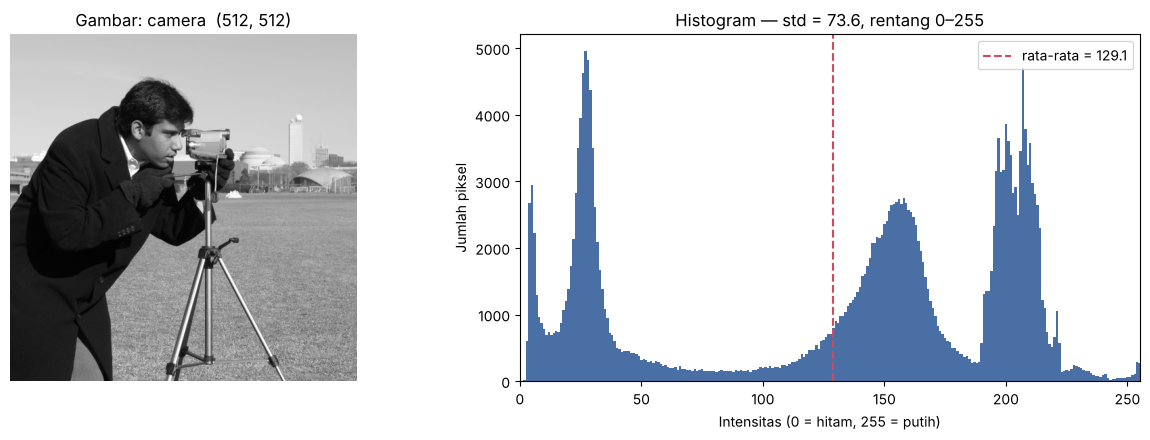

Statistik: {'rata-rata': 129.06, 'median': 152.0, 'std': 73.64, 'min': 0, 'max': 255}
Piksel gelap    (0-63)   :  29.6 %
Piksel menengah (64-191) :  40.4 %
Piksel terang   (192-255):  30.1 %
Intensitas puncak terbesar tiap area -> gelap: 27 | menengah: 156 | terang: 204


In [5]:
img1 = load(SRC_TUGAS1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
show_with_hist(ax[0], ax[1], img1, f"Gambar: {SRC_TUGAS1}  {img1.shape}")
plt.tight_layout(); plt.show()

h1 = hist(img1); total = h1.sum()
print("Statistik:", stats(img1))
print(f"Piksel gelap    (0-63)   : {h1[:64].sum()/total*100:5.1f} %")
print(f"Piksel menengah (64-191) : {h1[64:192].sum()/total*100:5.1f} %")
print(f"Piksel terang   (192-255): {h1[192:].sum()/total*100:5.1f} %")
halus = np.convolve(h1, np.ones(9)/9, mode="same")
print("Intensitas puncak terbesar tiap area -> gelap:", halus[:64].argmax(),
      "| menengah:", 64 + halus[64:192].argmax(), "| terang:", 192 + halus[192:].argmax())

### Analisis Tugas 1

Histogram gambar *cameraman* berbentuk **multimodal** dengan tiga kelompok puncak:

- **Puncak gelap (±0–35, tertinggi di ±27):** jas hitam, rambut, dan bayangan juru kamera. Sekitar 29,6% piksel bernilai di bawah 64.
- **Puncak menengah (±130–180, sekitar 155):** area rumput di latar depan.
- **Puncak terang (±190–220, tertinggi di ±205):** langit dan gedung di latar belakang. Sekitar 30,1% piksel bernilai ≥ 192.

Di antara puncak gelap dan puncak rumput terdapat **lembah lebar (±50–110)**, artinya hanya sedikit piksel bernada abu-abu tengah. Nilai piksel memenuhi seluruh rentang 0–255 dengan standar deviasi besar (±73,6), sehingga gambar ini **sudah memiliki kontras tinggi** dan objek terpisah jelas dari latar. Histogram seperti ini cocok untuk segmentasi dengan *thresholding*, misalnya threshold di sekitar lembah (±80) untuk memisahkan orang dari latar belakang.

---
## Tugas 2 — Perbandingan Kecerahan
Gunakan dua gambar berbeda, satu gelap dan satu terang. Bandingkan nilai rata-rata intensitasnya.

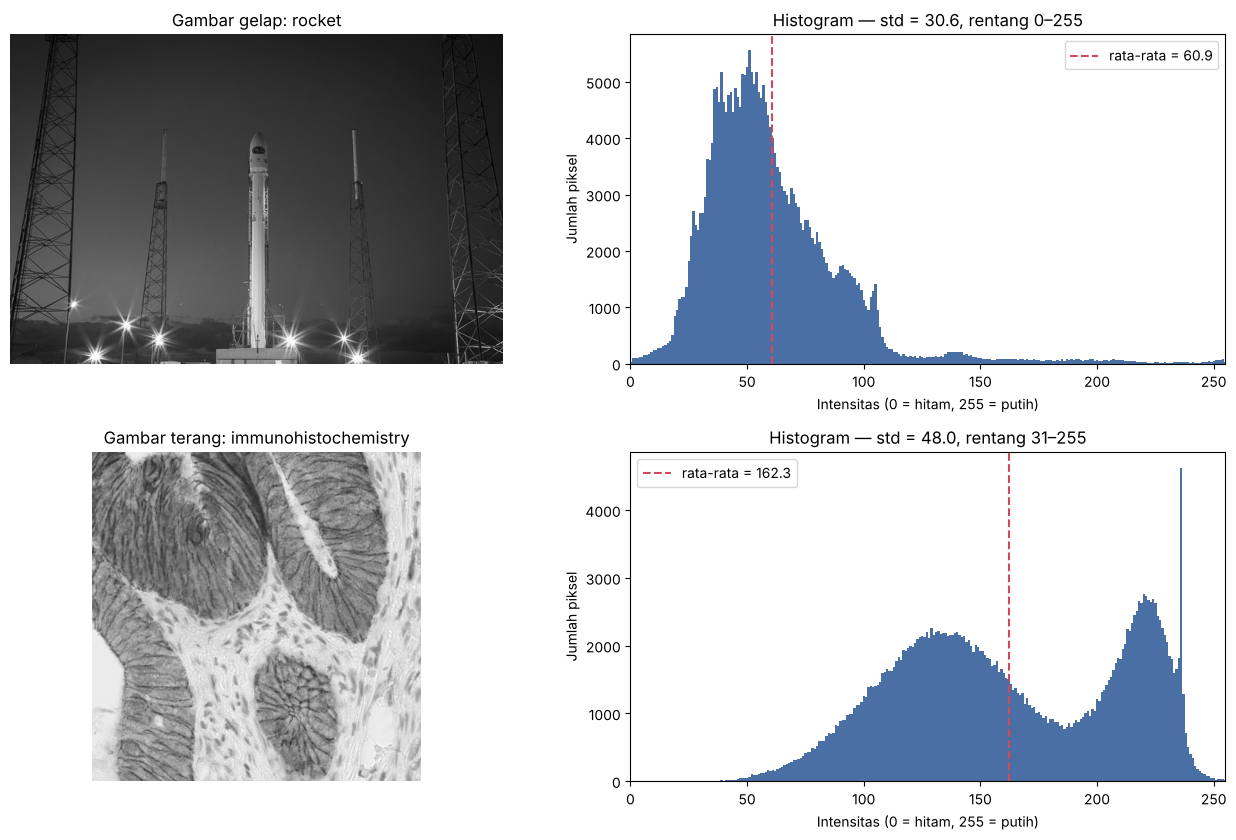

                 Gelap    Terang
rata-rata        60.86    162.35
median            55.0     156.0
std              30.61     47.96
min                  0        31
max                255       255

Selisih rata-rata : 101.5
Rasio rata-rata   : 2.67x


In [6]:
gelap, terang = load(SRC_GELAP), load(SRC_TERANG)
fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))
show_with_hist(ax[0, 0], ax[0, 1], gelap, f"Gambar gelap: {SRC_GELAP}")
show_with_hist(ax[1, 0], ax[1, 1], terang, f"Gambar terang: {SRC_TERANG}")
plt.tight_layout(); plt.show()

sg, st = stats(gelap), stats(terang)
print(f"{'':12}{'Gelap':>10}{'Terang':>10}")
for k in sg:
    print(f"{k:12}{sg[k]:>10}{st[k]:>10}")
print(f"\nSelisih rata-rata : {st['rata-rata'] - sg['rata-rata']:.1f}")
print(f"Rasio rata-rata   : {st['rata-rata'] / sg['rata-rata']:.2f}x")

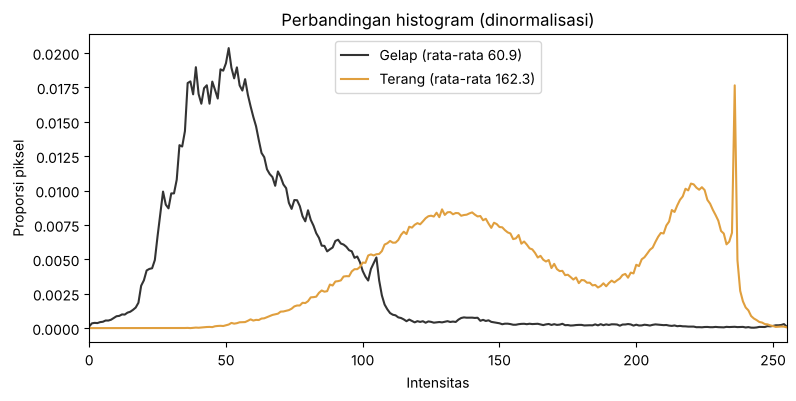

In [7]:
plt.figure(figsize=(9, 4))
plt.plot(hist(gelap) / gelap.size, label=f"Gelap (rata-rata {gelap.mean():.1f})", color="#333")
plt.plot(hist(terang) / terang.size, label=f"Terang (rata-rata {terang.mean():.1f})", color="#e09f3e")
plt.xlim(0, 255); plt.xlabel("Intensitas"); plt.ylabel("Proporsi piksel")
plt.title("Perbandingan histogram (dinormalisasi)"); plt.legend(); plt.show()

### Analisis Tugas 2

| | Gambar gelap (*rocket*) | Gambar terang (*immunohistochemistry*) |
|---|---|---|
| Rata-rata intensitas | **60,9** | **162,3** |
| Median | 55 | 156 |
| Std | 30,6 | 48,0 |
| Rentang | 0–255 | 31–255 |

- Rata-rata gambar terang lebih tinggi sekitar **101 tingkat** (±2,7 kali gambar gelap).
- Histogram gambar gelap **menumpuk di sisi kiri** (intensitas rendah), sedangkan histogram gambar terang **bergeser ke kanan** dan tidak memiliki piksel di bawah 31.
- Jadi **nilai rata-rata intensitas dapat dipakai sebagai ukuran kecerahan**: semakin besar rata-ratanya, semakin terang gambarnya. Rata-rata tidak menggambarkan kontras. Kontras dilihat dari lebar sebaran histogram (std).

---
## Tugas 3 — Histogram Equalization
Bandingkan gambar asli dengan gambar hasil equalization. Apakah kontras meningkat?

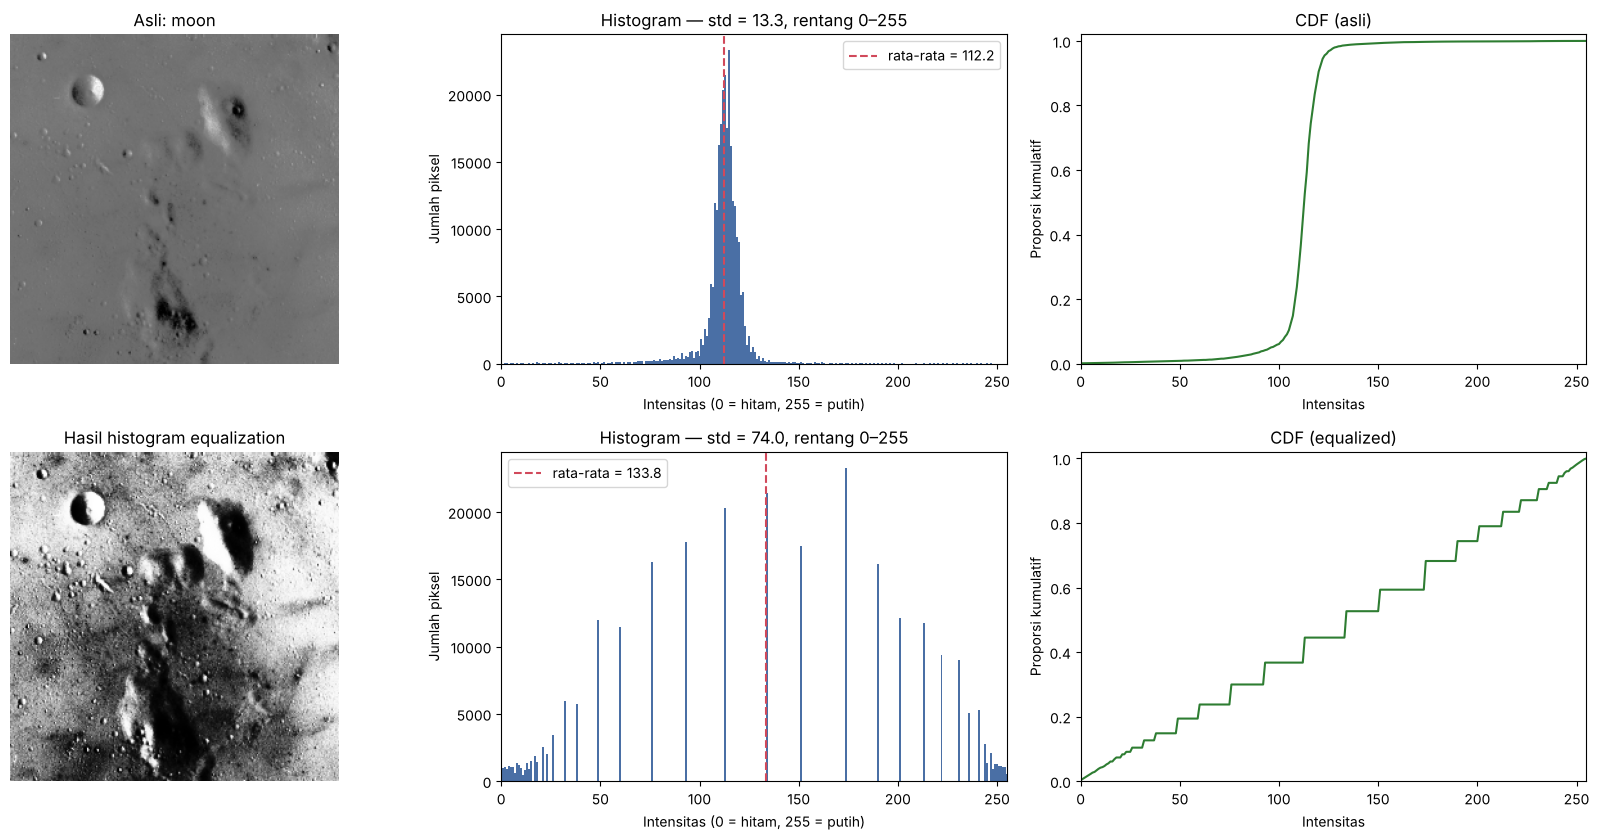

In [8]:
asli = load(SRC_EQ)
eq = cv2.equalizeHist(asli)

fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
show_with_hist(ax[0, 0], ax[0, 1], asli, f"Asli: {SRC_EQ}")
show_with_hist(ax[1, 0], ax[1, 1], eq, "Hasil histogram equalization")
for row, im, lab in [(0, asli, "asli"), (1, eq, "equalized")]:
    cdf = hist(im).cumsum(); cdf /= cdf[-1]
    ax[row, 2].plot(cdf, color="#2e7d32"); ax[row, 2].set_xlim(0, 255); ax[row, 2].set_ylim(0, 1.02)
    ax[row, 2].set_title(f"CDF ({lab})"); ax[row, 2].set_xlabel("Intensitas"); ax[row, 2].set_ylabel("Proporsi kumulatif")
plt.tight_layout(); plt.show()

In [9]:
sa, se = stats(asli), stats(eq)
p_asli, p_eq = np.percentile(asli, [5, 95]), np.percentile(eq, [5, 95])
print(f"{'':12}{'Asli':>10}{'Equalized':>12}")
for k in sa:
    print(f"{k:12}{sa[k]:>10}{se[k]:>12}")
print(f"\n90% piksel asli berada di      : {p_asli[0]:.0f}–{p_asli[1]:.0f} (lebar {p_asli[1]-p_asli[0]:.0f})")
print(f"90% piksel equalized berada di : {p_eq[0]:.0f}–{p_eq[1]:.0f} (lebar {p_eq[1]-p_eq[0]:.0f})")
print(f"Kenaikan std (kontras)         : {se['std']/sa['std']:.1f}x")

                  Asli   Equalized
rata-rata       112.17      133.76
median           113.0       134.0
std              13.33       74.01
min                  0           0
max                255         255

90% piksel asli berada di      : 96–123 (lebar 27)
90% piksel equalized berada di : 13–244 (lebar 231)
Kenaikan std (kontras)         : 5.6x


### Analisis Tugas 3

| | Asli | Setelah equalization |
|---|---|---|
| Rata-rata | 112,2 | 133,8 |
| Std (ukuran kontras) | **13,3** | **74,0** |
| 90% piksel berada di | 96–123 (lebar 27) | 13–244 (lebar 231) |

**Ya, kontras meningkat signifikan.**

- Histogram gambar asli **sempit dan menumpuk** di sekitar 110–120, sehingga gambar terlihat abu-abu datar dan detail kawah sulit terlihat.
- Setelah equalization, piksel **tersebar ke hampir seluruh rentang 0–255** dan standar deviasi naik ±5,6 kali. Detail kawah dan tekstur permukaan bulan menjadi jauh lebih jelas.
- Kurva **CDF** yang semula berbentuk tangga curam berubah menjadi **hampir garis lurus**. Inilah tujuan equalization: membuat distribusi kumulatif intensitas mendekati linear (seragam).

Catatan:
- Histogram hasil terlihat berupa batang-batang terpisah, bukan rata sempurna. Penyebabnya, jumlah tingkat abu-abu aslinya sedikit dan equalization hanya **meregangkan jarak** antar tingkat, tidak menciptakan tingkat baru.
- Equalization juga dapat **memperkuat noise** dan membuat sebagian area terlalu terang atau gelap. Alternatif yang lebih halus adalah CLAHE (*Contrast Limited Adaptive Histogram Equalization*).

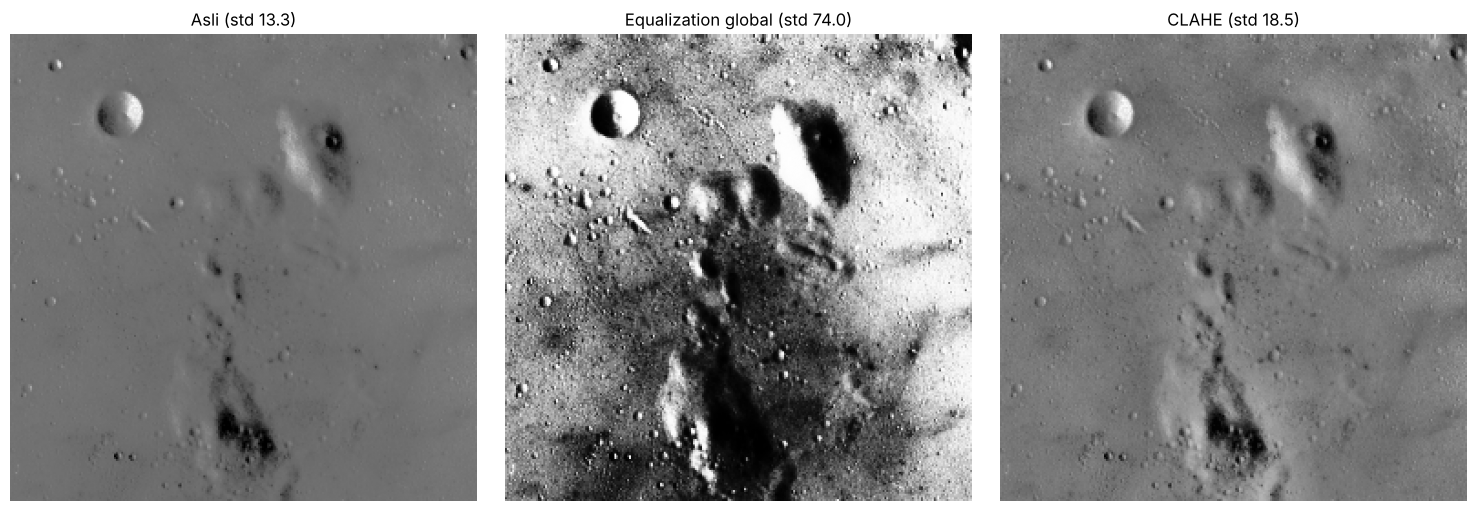

In [10]:
# Tambahan: perbandingan dengan CLAHE
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(asli)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [asli, eq, clahe], ["Asli", "Equalization global", "CLAHE"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(f"{t} (std {im.std():.1f})"); a.axis("off")
plt.tight_layout(); plt.show()

---
## Tugas 4 — Kesimpulan

Histogram adalah representasi distribusi intensitas piksel yang sederhana tetapi sangat informatif dalam pengolahan citra digital. Manfaatnya antara lain:

1. **Menilai kecerahan.** Posisi histogram dan nilai rata-rata intensitas menunjukkan apakah citra gelap, normal, atau terang (Tugas 2).
2. **Menilai kontras.** Lebar sebaran histogram (standar deviasi atau rentang) menunjukkan kontras. Histogram yang sempit berarti kontras rendah (Tugas 1 dan 3).
3. **Dasar perbaikan citra.** Teknik seperti *histogram equalization*, CLAHE, dan *contrast stretching* memanfaatkan histogram dan CDF untuk meningkatkan kontras secara otomatis (Tugas 3).
4. **Segmentasi.** Lembah di antara puncak histogram dapat dipakai sebagai nilai *threshold* untuk memisahkan objek dari latar belakang, misalnya dengan metode Otsu (Tugas 1).
5. **Analisis dan kontrol kualitas.** Histogram membantu mendeteksi *underexposure*, *overexposure*, atau *clipping*, serta membandingkan karakteristik antar citra.

Dengan demikian, histogram berfungsi sebagai **alat diagnosis kondisi citra** sekaligus **dasar bagi berbagai teknik peningkatan kualitas dan segmentasi citra digital**.